In [12]:
import numpy as np
import pandas as pd

In [13]:
def load_mean_adj(graph_path, label_path):
    graphs = np.load(graph_path)
    adj = graphs.mean(axis=0)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].astype(str).str.strip().values
    return adj, labels


A1, L1 = load_mean_adj(
    './result/wo_layer/stage1/tuning/bs8_dp0.1_sw1.0/dynamic_full_graphs.npy',
    './result/wo_layer/stage1/df_scaled.csv'
)

A2, L2 = load_mean_adj(
    './result/wo_layer/stage2/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy',
    './result/wo_layer/stage2/df_scaled.csv'
)

A3, L3 = load_mean_adj(
    './result/wo_layer/stage3/tuning/bs32_dp0.8_sw1.0/dynamic_full_graphs.npy',
    './result/wo_layer/stage3/df_scaled.csv'
)

In [17]:
import numpy as np

def analyze_ei_with_density(adj, fc_min_abs=0.01, min_connections=5):
    mask = np.abs(adj) >= fc_min_abs
    n_connections = np.sum(mask, axis=0)
    valid_regions = n_connections >= min_connections
    E = np.sum(np.where((adj > 0) & mask, adj, 0), axis=0)
    I = np.sum(np.where((adj < 0) & mask, np.abs(adj), 0), axis=0)
    ei_prop = E / (E + I + 1e-8)
    valid_ei = ei_prop[valid_regions]
    valid_n = n_connections[valid_regions]
    bio_lower, bio_upper = 0.75, 0.90
    return {
        'ei_proportion': valid_ei,
        'n_connections': valid_n,
        'n_valid_regions': int(np.sum(valid_regions)),
        'total_regions': int(len(ei_prop)),
        'mean_ei': float(np.mean(valid_ei)),
        'median_ei': float(np.median(valid_ei)),
        'pct_e_dominant': float(np.mean(valid_ei > 0.5) * 100),
        'pct_bio_range': float(np.mean((valid_ei >= bio_lower) & (valid_ei <= bio_upper)) * 100),
        'ref_range': (bio_lower, bio_upper)
    }

stats1 = analyze_ei_with_density(A1, min_connections=5)
stats2 = analyze_ei_with_density(A2, min_connections=5)
stats3 = analyze_ei_with_density(A3, min_connections=5)

for name, stats in zip(['Stage1', 'Stage2', 'Stage3'], [stats1, stats2, stats3]):
    print(f"\n=== {name} (Regions with >= 5 connections) ===")
    print(f"Valid regions: {stats['n_valid_regions']}/{stats['total_regions']} ({stats['n_valid_regions']/stats['total_regions']*100:.1f}%)")
    print(f"Average connections: {np.mean(stats['n_connections']):.1f}")
    print(f"Mean E/I proportion: {stats['mean_ei']:.3f}  (E:I ~ {stats['mean_ei']/(1-stats['mean_ei']):.1f}:1)")
    print(f"Median E/I proportion: {stats['median_ei']:.3f}  (E:I ~ {stats['median_ei']/(1-stats['median_ei']):.1f}:1)")
    print(f"Percentage of E > I regions: {stats['pct_e_dominant']:.1f}%")
    print(f"Percentage within reference range [{stats['ref_range'][0]}-{stats['ref_range'][1]}]: {stats['pct_bio_range']:.1f}%")


=== Stage1 (Regions with >= 5 connections) ===
Valid regions: 52/89 (58.4%)
Average connections: 16.0
Mean E/I proportion: 0.617  (E:I ~ 1.6:1)
Median E/I proportion: 0.656  (E:I ~ 1.9:1)
Percentage of E > I regions: 75.0%
Percentage within reference range [0.75-0.9]: 13.5%

=== Stage2 (Regions with >= 5 connections) ===
Valid regions: 52/89 (58.4%)
Average connections: 16.1
Mean E/I proportion: 0.688  (E:I ~ 2.2:1)
Median E/I proportion: 0.751  (E:I ~ 3.0:1)
Percentage of E > I regions: 84.6%
Percentage within reference range [0.75-0.9]: 40.4%

=== Stage3 (Regions with >= 5 connections) ===
Valid regions: 52/89 (58.4%)
Average connections: 16.0
Mean E/I proportion: 0.692  (E:I ~ 2.3:1)
Median E/I proportion: 0.759  (E:I ~ 3.2:1)
Percentage of E > I regions: 80.8%
Percentage within reference range [0.75-0.9]: 40.4%


Figure saved to ei_by_region.pdf


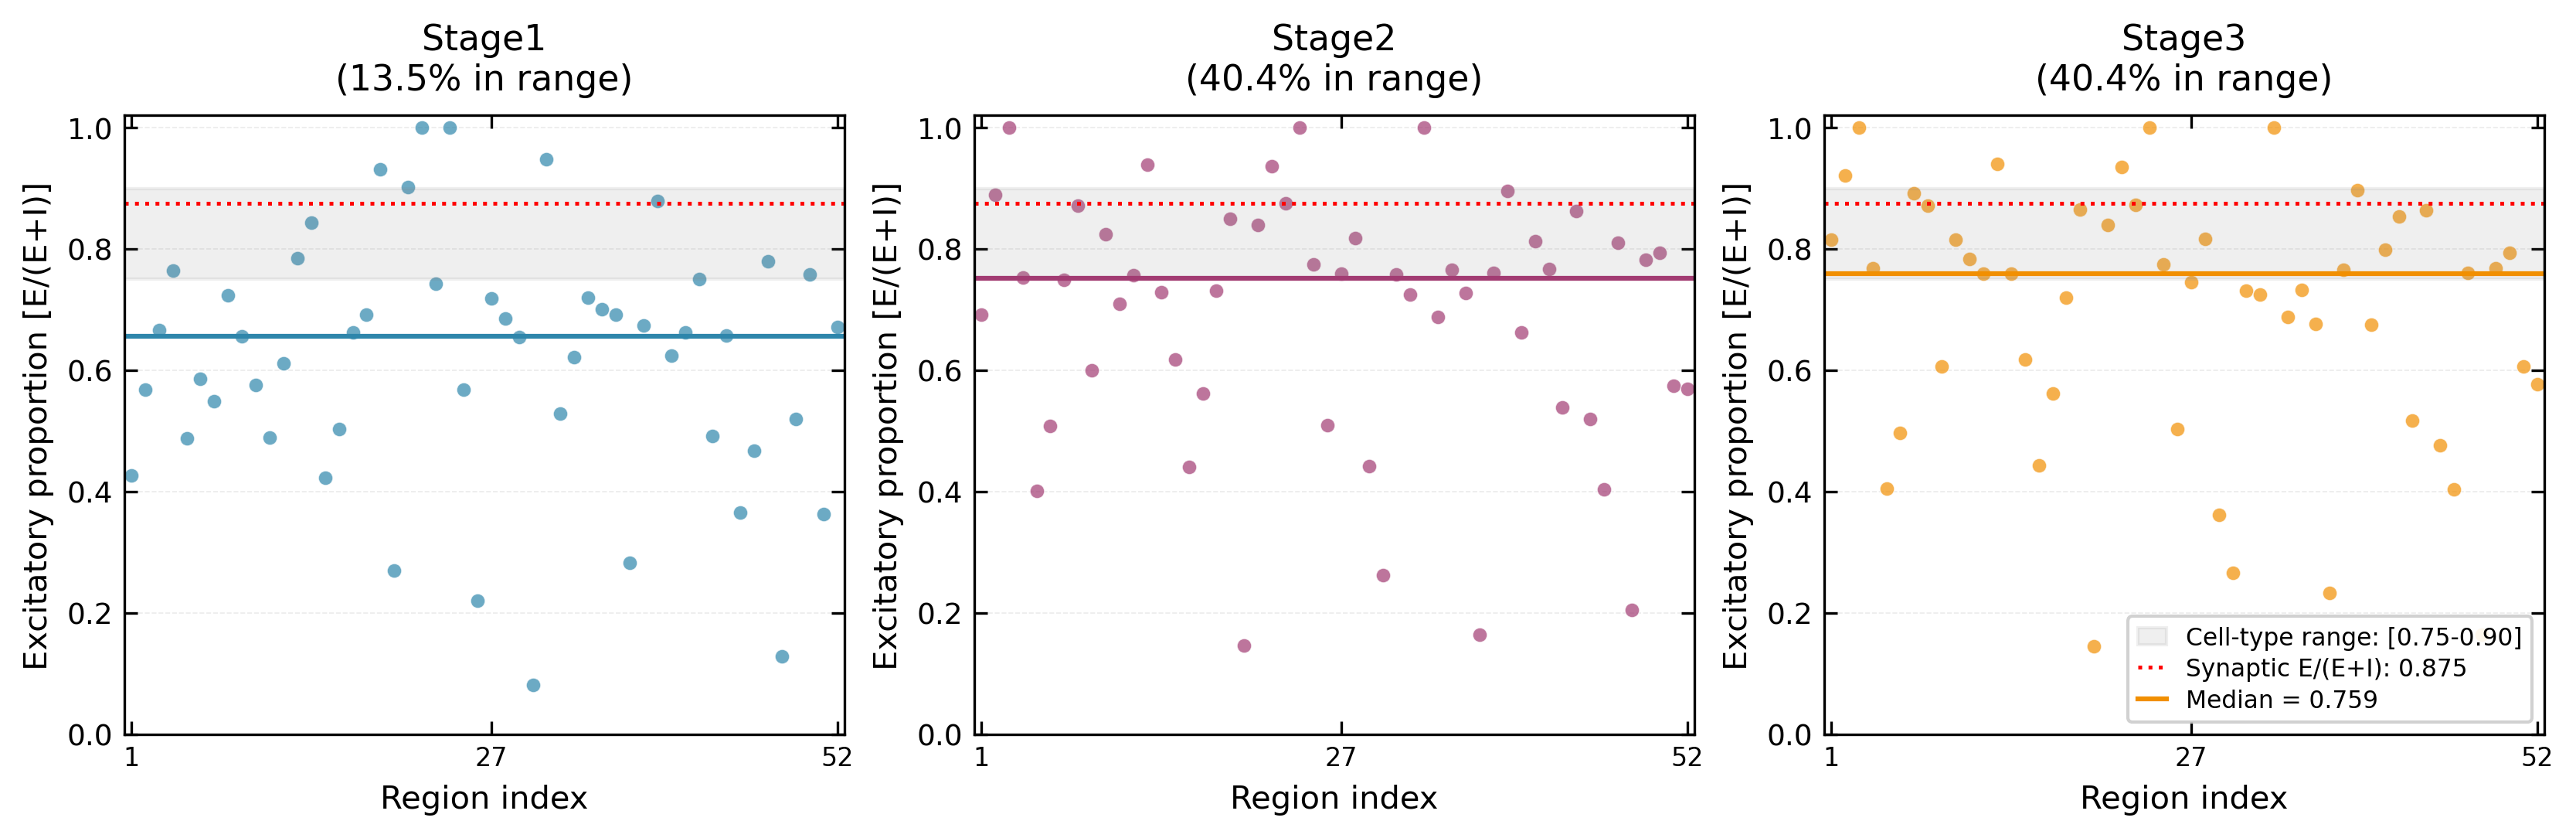

In [20]:
import numpy as np
import matplotlib.pyplot as plt

def plot_ei_by_region(stats_dict, stage_names, region_labels=None, 
                      bio_range=(0.75, 0.90), peng_ei_prop=0.874, 
                      output_path=None, dpi=300):
    plt.rcParams.update({
        'font.size': 9,
        'axes.labelsize': 10,
        'axes.titlesize': 11,
        'xtick.labelsize': 8,
        'ytick.labelsize': 9,
        'legend.fontsize': 8,
        'axes.linewidth': 0.8,
        'xtick.major.width': 0.8,
        'ytick.major.width': 0.8,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'xtick.top': True,
        'ytick.right': True,
        'figure.dpi': dpi
    })
    
    colors = ['#2E86AB', '#A23B72', '#F18F01']
    bio_lower, bio_upper = bio_range
    
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), constrained_layout=True)
    
    for ax, stats, name, color in zip(axes, stats_dict.values(), stage_names, colors):
        ei_vals = stats['ei_proportion']
        n_regions = len(ei_vals)
        x_pos = np.arange(n_regions)
        
        in_range = (ei_vals >= bio_lower) & (ei_vals <= bio_upper)
        pct_in_range = np.mean(in_range) * 100
        
        ax.scatter(x_pos, ei_vals, c=color, alpha=0.7, s=20, 
                  edgecolors='white', linewidth=0.3, rasterized=True)
        
        ax.axhspan(bio_lower, bio_upper, color='gray', alpha=0.12, 
                  label='Cell-type range: [0.75-0.90]')
        ax.axhline(peng_ei_prop, color='red', linestyle=':', linewidth=1.2, 
                  label=f'Synaptic E/(E+I): {peng_ei_prop:.3f}')
        ax.axhline(np.median(ei_vals), color=color, linestyle='-', linewidth=1.5, 
                  label=f'Median = {np.median(ei_vals):.3f}')
        
        ax.set_xlabel('Region index')
        ax.set_ylabel('Excitatory proportion [E/(E+I)]')
        ax.set_title(f'{name}\n({pct_in_range:.1f}% in range)', pad=8)
        
        ax.set_xlim(-0.5, n_regions - 0.5)
        ax.set_ylim(0, 1.02)
        
        if n_regions <= 20 and region_labels is not None:
            valid_labels = region_labels[:n_regions]
            ax.set_xticks(x_pos)
            ax.set_xticklabels(valid_labels, rotation=90, fontsize=6)
        else:
            ax.set_xticks([0, n_regions//2, n_regions-1])
            ax.set_xticklabels([1, n_regions//2+1, n_regions])
        
        ax.grid(axis='y', alpha=0.25, linestyle='--', linewidth=0.4)
        ax.set_axisbelow(True)
        
        if name == stage_names[-1]:
            ax.legend(frameon=True, framealpha=0.9, fontsize=7.5, 
                     labelspacing=0.3, handlelength=1.2, loc='lower right')
    
    for ax in axes.flat:
        ax.tick_params(axis='both', which='major', length=4, width=0.8)
        ax.tick_params(axis='both', which='minor', length=2, width=0.5)
    
    if output_path:
        plt.savefig(output_path, dpi=dpi, bbox_inches='tight', 
                   format='pdf', transparent=False)
        print(f"Figure saved to {output_path}")
    
    plt.show()
    return fig

fig = plot_ei_by_region(
    {'Stage1': stats1, 'Stage2': stats2, 'Stage3': stats3},
    ['Stage1', 'Stage2', 'Stage3'],
    region_labels=L1,
    bio_range=(0.75, 0.90),
    peng_ei_prop=0.875,
    output_path='ei_by_region.pdf'
)